In [1]:
import h5py
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import scienceplots
plt.style.use(['science', 'no-latex'])

from pybaselines import Baseline, utils
from datetime import datetime, timezone
# from scipy.optimize import curve_fit
# from scipy.signal import savgol_filter
# from scipy.ndimage import binary_dilation
from scipy.signal import find_peaks

from astropy.stats import median_absolute_deviation as MAD
from astropy.modeling import models, fitting
from astropy.convolution import convolve_models

from MPG_HDF5_libs import *

In [2]:
# configuration for the plots
plt.style.use(['science', 'no-latex'])

plt.rcParams.update({
    "axes.labelsize": 14,  # Font size for axis labels
    "xtick.labelsize": 16,  # Font size for x-axis tick labels
    "ytick.labelsize": 16   # Font size for y-axis tick labels
})   

plt.rcParams['axes.unicode_minus'] = False


# Acessing the data

In [3]:
filename = ('/home/chavango/Master/DATA/SKAMPI_data/EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5')


# Let's porint the structure of the hdf5 file
def print_hdf5_structure(name, obj, lines):
    indent = '  ' * name.count('/')
    if isinstance(obj, h5py.Group):
        lines.append(f"{indent}Group: {name}")
    elif isinstance(obj, h5py.Dataset):
        lines.append(f"{indent}Dataset: {name}, Shape: {obj.shape}, Dtype: {obj.dtype}")
        
with h5py.File(filename, "r") as f:
    lines = []  # store all lines here
    f.visititems(lambda name, obj: print_hdf5_structure(name, obj, lines))

    # Print the last 20 lines of the structure
    print("\n".join(lines[-20:]))

      Dataset: scan/001/P1_ND0/dec, Shape: (666,), Dtype: float64
      Dataset: scan/001/P1_ND0/elevation, Shape: (666,), Dtype: float64
      Dataset: scan/001/P1_ND0/integration_time, Shape: (666, 1), Dtype: float64
      Dataset: scan/001/P1_ND0/mask, Shape: (666, 65537), Dtype: bool
      Dataset: scan/001/P1_ND0/power, Shape: (666,), Dtype: float64
      Dataset: scan/001/P1_ND0/ra, Shape: (666,), Dtype: float64
      Dataset: scan/001/P1_ND0/saturated_samples, Shape: (666, 1), Dtype: uint64
      Dataset: scan/001/P1_ND0/spectrum, Shape: (666, 65537), Dtype: float32
      Dataset: scan/001/P1_ND0/timestamp, Shape: (666, 1), Dtype: float64
    Group: scan/001/P1_ND1
      Dataset: scan/001/P1_ND1/azimuth, Shape: (666,), Dtype: float64
      Dataset: scan/001/P1_ND1/dec, Shape: (666,), Dtype: float64
      Dataset: scan/001/P1_ND1/elevation, Shape: (666,), Dtype: float64
      Dataset: scan/001/P1_ND1/integration_time, Shape: (666, 1), Dtype: float64
      Dataset: scan/001/P1_ND1

In [4]:
# import xarray as xr

In [5]:
# # plot the power spectrum
# with h5py.File(filename,'r') as f:
#     for g in groups:
#         spectrum = f[f"{g}/spectrum"]
#         # Average convert the power spectrum to dB

#         # define the varibles
#         time = f['scan/000/P0_ND0/timestamp'][:,0] # shape  (666,)
#         freq = f[f"{g}/frequency"]    # convert Hz -> GHz shape (65537,)

#         print(f"Spectrum shape: {spectrum.shape}, Freq shape: {freq.shape}, Time shape: {time.shape}")

#         spect = xr.DataArray(
#             spectrum, # this is from Sam prob array
#             dims=("time", "freqs"),
#             coords={
#                 "time": time,  # dummy time coord; replace if available
#                 "freqs": freq 
#             },
#         )

#         break




In [6]:
# spect

In [7]:
# spect['time'][0]

In [8]:
# spect.sel(time=slice('1.681843e+09', '1.681843e+09'))

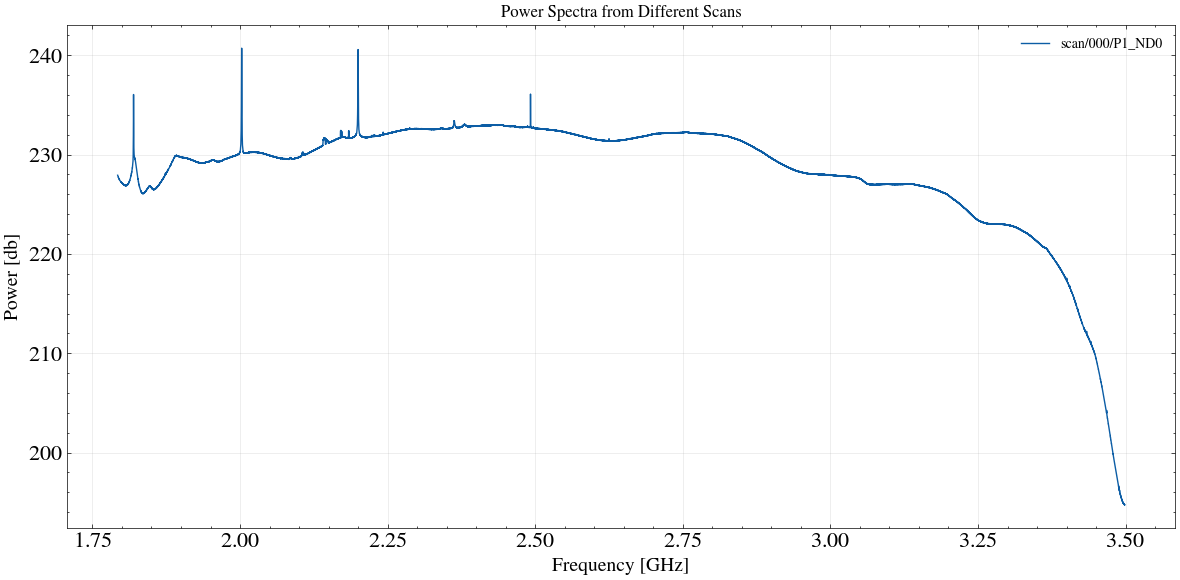

In [9]:
# Select different group os data

groups = [
     "scan/000/P1_ND0",
    #  "scan/000/P1_ND1",
    # "scan/001/P0_ND0",
    # "scan/001/P0_ND1",
    # "scan/001/P1_ND0",
    # "scan/001/P1_ND1"
]


# plot the power spectrum
with h5py.File(filename,'r') as f:
    for g in groups:
        spectrum = f[f"{g}/spectrum"][:,1600:-60]
        # Average convert the power spectrum to dB
        spectrum_dB = 10*np.log10(np.mean(spectrum**2, axis=0)) # in dB

        # define the varibles
        time = f['scan/000/P0_ND0/timestamp'][:,0]  # shape  (666,)
        freq = f[f"{g}/frequency"][1600:-60] / 1e9   # convert Hz -> GHz shape (65537,)



        # Plot
        plt.figure(figsize=(12,6))
        plt.plot(freq, spectrum_dB, label=g)

        plt.xlabel("Frequency [GHz]")
        plt.ylabel("Power [db]")
        plt.title("Power Spectra from Different Scans")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

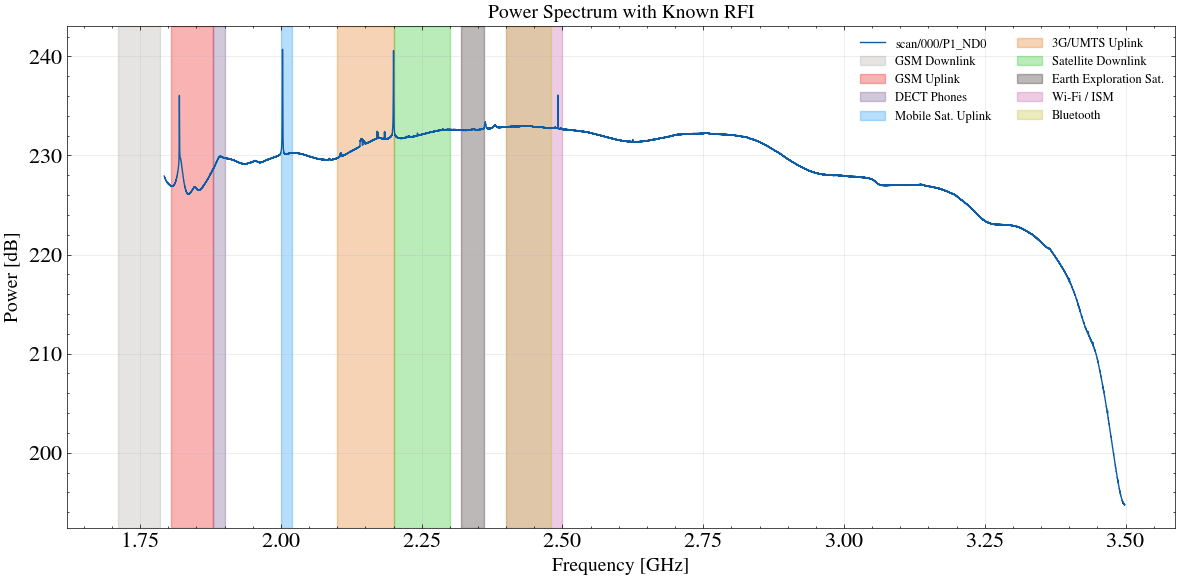

In [10]:

# Define RFI bands (GHz) for MeerKAT S-band (1.75–3.5 GHz)
rfi_bands = {
    "GSM Downlink": (1.71,  1.785),  # Global System for Mobile Communications
    "GSM Uplink": (1.805, 1.88),
    "DECT Phones": (1.88, 1.9),   # Digital Enhanced Cordless Telecommunications
    "Mobile Sat. Uplink": (2.00, 2.02),
    "3G/UMTS Uplink": (2.10, 2.20),   # Universal Mobile Telecommunications System
    "Satellite Downlink": (2.20, 2.30),
    "Earth Exploration Sat.": (2.32, 2.36),
    "Wi-Fi / ISM": (2.40, 2.50),   # Industrial, Scientific, and Medical band 
    "Bluetooth": (2.40, 2.48),
    #"Radar (Weather/ATC)": (2.70, 2.90),
    #"5G / Broadband": (3.40, 3.50)
}

colors = [
    "#AFA5A5", "#f1060661", "#67498361", "#1196f684","#e36f098b","#1CC21C79",
    "#22141153", "#c855a686", "#bdbd2276", "#837e7e5b"
]

# Plot with RFI bands
with h5py.File(filename,'r') as f:
    for g in groups:

    
        # Plot
        plt.figure(figsize=(12,6))
        plt.plot(freq, spectrum_dB, label=g)

        # --- Overlay RFI bands ---
        for (label, (f_start, f_end)), color in zip(rfi_bands.items(), colors):
            plt.axvspan(f_start, f_end, color=color, alpha=0.3, label=label)

        # --- Labels and formatting ---
        plt.xlabel("Frequency [GHz]")
        plt.ylabel("Power [dB]")
        plt.title("Power Spectrum with Known RFI", fontsize=14)
        plt.legend(loc="upper right", fontsize=9, ncol=2)
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

# Detrend the signal

In [11]:
# Baseline correction

def base_correction(freq,power):
    """ 
    The function perform the baseline correction using the method: "Asymmetric Least Squar"

    Takes as entries:
    --------
    freq: array
    power: array

    Returns:
    ------
    The signal with the baseline corrected
    
    """

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=freq)
    bkg, params = baseline_fitter.asls(power, lam=1e7, p=0.02)

    # Step 2: Substract the baseline
    correct_baseline = power - bkg

    return correct_baseline



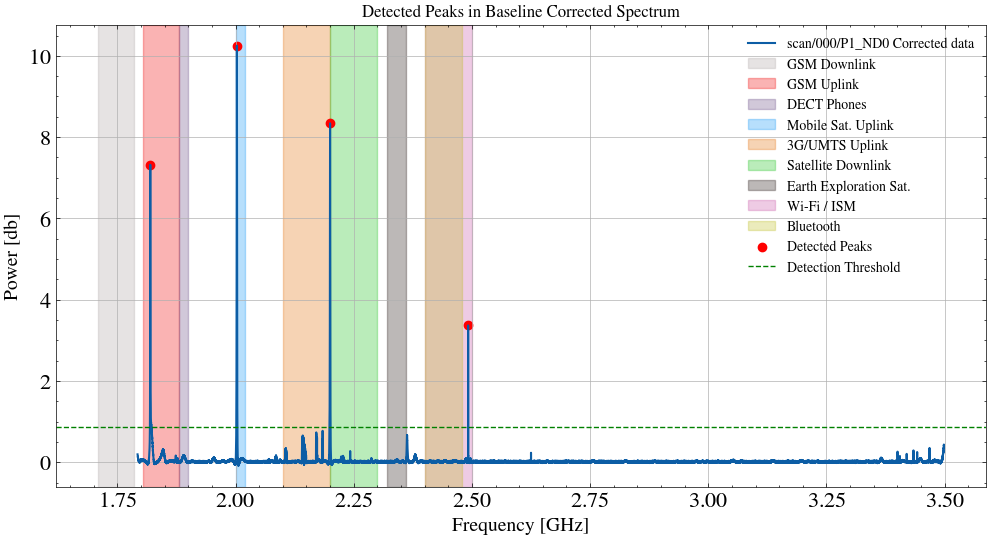

Detected peak frequencies (GHz): ['1.8196', '2.0028', '2.1999', '2.4920']


In [12]:
# Base line corrected and peaks detection
for g in groups:

    power_base_core = base_correction(freq, spectrum_dB)

        
    peaks, propreties = find_peaks(power_base_core, 
                                height=MAD(power_base_core) + 3*np.std(power_base_core), 
                                distance=10,
                                prominence=1.5
                                )


    plt.figure(figsize=(12, 6))
    plt.plot(freq, power_base_core, label=f'{g} Corrected data', lw=1.5)
    # --- Overlay RFI bands ---
    for (label, (f_start, f_end)), color in zip(rfi_bands.items(), colors):
        plt.axvspan(f_start, f_end, color=color, alpha=0.3, label=label)

    plt.scatter(freq[peaks], power_base_core[peaks], color='red', label='Detected Peaks')
    plt.axhline(y=MAD(power_base_core) + 3*np.std(power_base_core), color='green', linestyle='--', label='Detection Threshold')
    plt.xlabel("Frequency [GHz]")
    plt.ylabel("Power [db]")
    plt.title("Detected Peaks in Baseline Corrected Spectrum")
    plt.grid()
    plt.legend()
    plt.show()


    formatted_freqs = [f"{f:.4f}" for f in freq[peaks]]
    print(f"Detected peak frequencies (GHz): {formatted_freqs}")

# Analysing each band correpted 

In [13]:
# Define a function to quantify the RFI width
def quantify_RFI_width(freq, power):
    """
    Quantify how wide an RFI peak is in frequency.

    Parameters:
    freq : array
        Frequency array.
    power : array
        Power array with baseline corrected.
    mask : boolean array
        Mask to select the frequency window of interest.

    Returns:
    start_freq : float
        Frequency where power rises above threshold.
    end_freq : float
        Frequency where power falls below threshold.
    peak_freq : float
        Frequency of the peak power.
    peak_power : float
        Value of the peak power.
    """


    # --- 1) Find where power rises above zero ---
    threshold = 0.05  # small threshold 
    above_threshold = np.where(power > threshold)[0]

    if len(above_threshold) > 0:
        start_index = above_threshold[0]
        end_index = above_threshold[-1]
        start_freq = freq[start_index]
        end_freq = freq[end_index]
    else:
        start_freq = end_freq = np.nan
        print("No significant power detected in the masked range.")

    # --- 2) Find the frequency of the peak ---
    peak_index = np.argmax(power)
    peak_freq = freq[peak_index]
    peak_power = power[peak_index]


    print(f"Start Frequency: {start_freq:.4f} GHz")
    print(f"End Frequency: {end_freq:.4f} GHz")
    print(f"Peak Frequency: {peak_freq:.4f} GHz with Power: {peak_power:.4f} dB")


    # Number of channels corrupted.
    delta_frequency = (freq[1] - freq[0])  # spectral resolution / channel width
    chans = ((end_freq - start_freq) / delta_frequency)


    print(f'Number off corrupted channels: {chans: .1f}')


    # --- Plot results ---
    plt.figure(figsize=(12,6))
    plt.plot(freq, power, '.', color='steelblue', label='Data')
    plt.axvline(start_freq, color='green', linestyle='--', label='Start', alpha=1, linewidth=2)
    plt.axvline(peak_freq, color='red', linestyle='-', label='Peak', alpha=1,linewidth=2)
    plt.axvline(end_freq, color='orange', linestyle='--', label='End', alpha=1, linewidth=2)
    plt.xlabel('Frequency [GHz]', fontsize=22)
    plt.ylabel('Detrended Power [dB]', fontsize=22)
    plt.legend(fontsize=14)
    plt.legend(fontsize=17)
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.grid(linestyle='--')

    return start_freq, end_freq, peak_freq, peak_power



# Waterfall plot function for specified frequency range
def waterfall_timevsfreq(time, freq, spectrum, freq_mask):
    """
    Generate a waterfall plot of power vs time and frequency.

    Parameters:
    time : array
        Time array in seconds since epoch.
    freq : array
        Frequency array in GHz.
    spectrum : 2D array
        Power spectrum with shape (time, frequency).
    freq_mask : boolean array
        Mask to select the frequency range of interest.

    Returns:
    None
        """
    # --- Convert Power Spectrum to dB ---
    # Adding 1e-12 avoids log of zero
    spectrum_db = 10 * np.log10(spectrum**2 + 1e-12)

    # Select the desired frequency channels
    power_channel = spectrum_db[:, freq_mask]

    # --- Convert Time to UTC Datetime ---
    time_utc = pd.to_datetime(time, unit="s", utc=True)

    # --- Select Frequency Range (GHz) ---
    freq_sel = freq[freq_mask]


    # --- Plot Waterfall (Time vs Frequency) ---
    plt.figure(figsize=(12, 6))
    plt.imshow(
        power_channel.T,             # transpose so freq is x-axis, time is y-axis
        aspect='auto', 
        origin='lower',
        extent=[0, len(time_utc), freq_sel.min(), freq_sel.max()],
        cmap='viridis'
    )

    cbar = plt.colorbar(label='Power [dB]')
    cbar.ax.tick_params(labelsize=14)       # set tick label size
    cbar.set_label('Power [dB]', fontsize=16)  # set label font size

    plt.xlabel('Time [UTC]',fontsize=16)
    plt.ylabel('Frequency [GHz]',fontsize=16)
    plt.title('Waterfall Plot: Time vs Frequency',fontsize=18)

    # --- X-axis: Time Ticks (UTC) ---
    n_ticks = 10
    tick_positions = np.linspace(0, len(time_utc) - 1, n_ticks, dtype=int)
    tick_labels = [time_utc[i].strftime("%H:%M:%S") for i in tick_positions]

    plt.xticks(tick_positions, tick_labels, rotation=45, ha='right')

    # --- Y-axis: Frequency in GHz ---
    plt.ylim(freq_sel.min(), freq_sel.max())
    plt.grid(linestyle='--')
    plt.tight_layout()


In [14]:
freq

array([1.79271126, 1.79273796, 1.79276466, ..., 3.49833107, 3.49835777,
       3.49838448], shape=(63877,))

In [15]:
# Spectral resolution in Hz
(freq[1]-freq[0])*1e9
#(((3.5-1.75)/65537)*1e9)

np.float64(26702.880859375)

In [16]:
def waterfall_timevsfreq1(time, freq, spectrum, freq_mask):
    """
    Generate a waterfall plot of power vs time and frequency.

    Parameters:
    time : array
        Time array in seconds since epoch.
    freq : array
        Frequency array in GHz.
    spectrum : 2D array
        Power spectrum with shape (time, frequency).
    freq_mask : boolean array
        Mask to select the frequency range of interest.

    Returns:
    None
    """

    # --- Convert Power Spectrum to dB ---
    spectrum_db = 10 * np.log10(spectrum**2 + 1e-12)

    # Select the desired frequency channels
    power_channel = spectrum_db[:, freq_mask]

    # --- Convert Time to UTC Datetime ---
    time_utc = pd.to_datetime(time, unit="s", utc=True)

    # --- Select Frequency Range (GHz) ---
    freq_sel = freq[freq_mask]

    # --- Plot Waterfall (Frequency on x, Time on y) ---
    plt.figure(figsize=(12, 6))
    plt.imshow(
        power_channel,
        aspect='auto',
        origin='lower',
        extent=[freq_sel.min(), freq_sel.max(), 0, len(time_utc)],
        cmap='viridis'
    )

    cbar = plt.colorbar(label='Power [dB]')
    cbar.ax.tick_params(labelsize=14)       # set tick label size
    cbar.set_label('Power [dB]', fontsize=16)  # set label font size
    
    plt.xlabel('Frequency [GHz]', fontsize=16)
    plt.ylabel('Time [UTC]', fontsize=16)
    #plt.title('Waterfall Plot: Time vs Frequency', fontsize=18)

    # --- Y-axis: Time Ticks (UTC) ---
    n_ticks = 10
    tick_positions = np.linspace(0, len(time_utc) - 1, n_ticks, dtype=int)
    tick_labels = [time_utc[i].strftime("%H:%M:%S") for i in tick_positions]
    plt.yticks(tick_positions, tick_labels)

    # --- X-axis: Frequency ---
    plt.xlim(freq_sel.min(), freq_sel.max())
    plt.grid(False)
    plt.tight_layout()


Start Frequency: 1.8164 GHz
End Frequency: 1.8271 GHz
Peak Frequency: 1.8196 GHz with Power: 7.3196 dB
Number off corrupted channels:  400.0


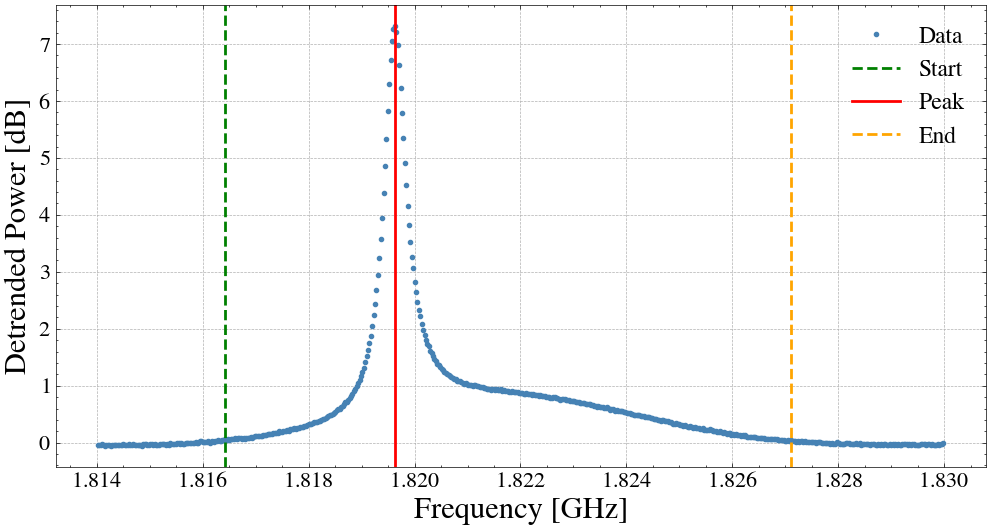

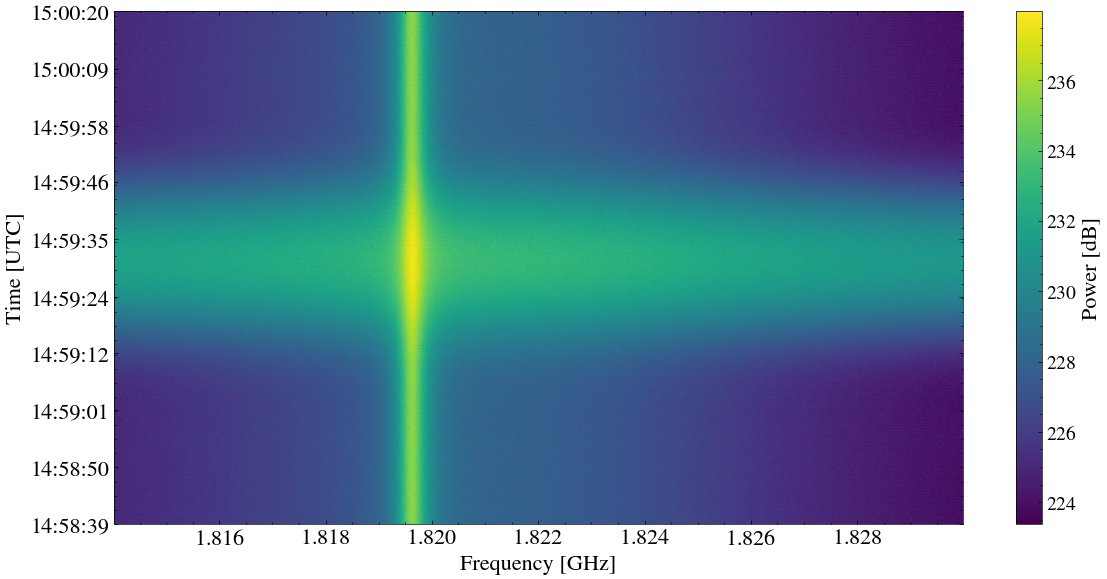

In [17]:
# define the window
mask1 = (freq > 1.814) & (freq < 1.83)
mask2 = (freq > 1.87) & (freq < 1.874) 
mask3 = (freq > 2.197) & (freq < 2.203) 
mask4 = (freq > 2.089) & (freq < 2.099) 
mask5 = (freq > 2.196) & (freq < 2.205)


fitted = quantify_RFI_width(freq[mask1], power_base_core[mask1])
waterfall = waterfall_timevsfreq1(time, freq, spectrum, mask1)
#waterfall = waterfall_timevsfreq(time, freq, spectrum, mask4)



# How can we detect the low level RFI? And what are the source of the low level RFI??

Detected peak > 1σ are frequencies (GHz): ['1.8196', '2.0028', '2.1421', '2.1703', '2.1707', '2.1723', '2.1841', '2.1845', '2.1999', '2.3627', '2.4920']
Detected peak > 3σ are frequencies (GHz): ['1.8196', '2.0028', '2.1999', '2.4920']


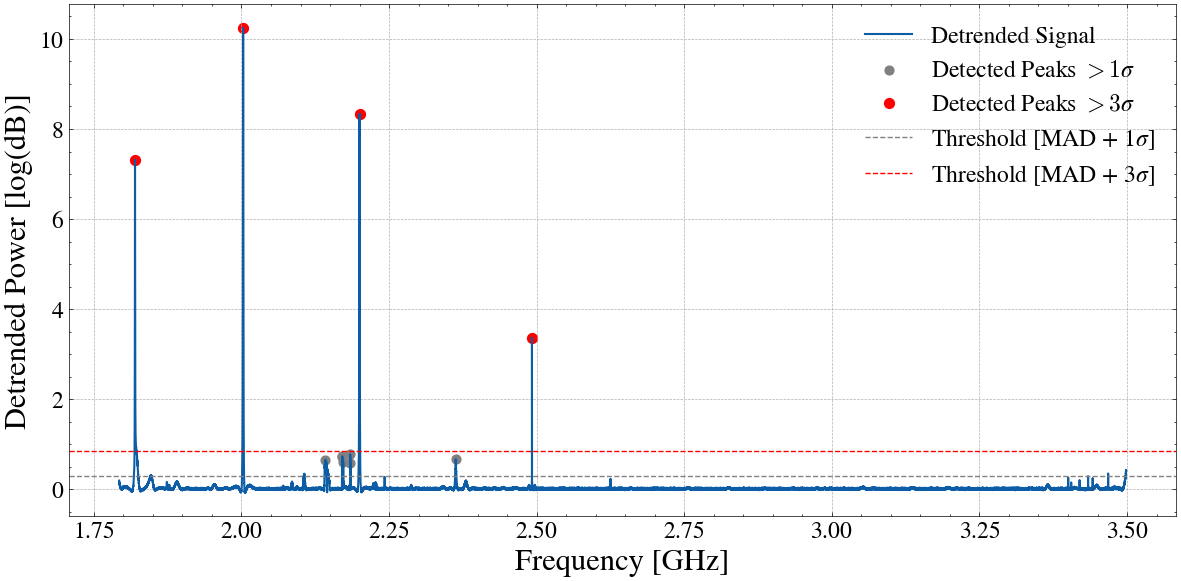

In [18]:
# Base line corrected and peaks detection
for g in groups:

    power_base_core = base_correction(freq, spectrum_dB)

        
    # Find peaks above 1 sigma from the MAD
    peaks, propreties = find_peaks(power_base_core, 
                                height=MAD(power_base_core) + np.std(power_base_core),
                                distance=10,
                                prominence=0.5
                                )
    # Find peaks above 3 sigma from the MAD
    peaks1, propreties1 = find_peaks(power_base_core, 
                                height=MAD(power_base_core) + 3*np.std(power_base_core),
                                distance=10,
                                prominence=0.5
                                )

    plt.figure(figsize=(12, 6))

    # --- Plot baseline-corrected spectrum ---
    plt.plot(freq, power_base_core, label=f'Detrended Signal', lw=1.5)

    # --- Plot detected peaks ---
    plt.scatter(freq[peaks], power_base_core[peaks], 
                color='gray', s=40, label='Detected Peaks $> 1σ$')

    plt.scatter(freq[peaks1], power_base_core[peaks1], 
                color='red', s=50, label='Detected Peaks $> 3σ$')

    # --- Plot threshold lines ---
    plt.axhline(y=MAD(power_base_core) + np.std(power_base_core), 
                color='gray', linestyle='--', label='Threshold [MAD + 1$σ$]')

    plt.axhline(y=MAD(power_base_core) + 3*np.std(power_base_core), 
            color='red', linestyle='--', label='Threshold [MAD + 3$σ$]')

    # --- Labels and formatting ---
    plt.xlabel("Frequency [GHz]",fontsize=22)
    plt.ylabel("Detrended Power [log(dB)]",fontsize=22)
    #plt.title("Detected Peaks in Baseline Corrected Spectrum", fontsize=18)
    plt.grid(True, linestyle='--')
    plt.tight_layout()
    plt.legend(fontsize=17)
    plt.xticks(fontsize=17)
    plt.yticks(fontsize=17)

#    plt.savefig(f'/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/Detected_Peaks_base_cor.png', dpi=300)
#    plt.savefig(f'/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/Detected_Peaks_base_cor.pdf', dpi=300)


    # --- Print detected peak frequencies ---
    formatted_freqs = [f"{f:.4f}" for f in freq[peaks]]
    formatted_freqs1 = [f"{f:.4f}" for f in freq[peaks1]]

    print(f"Detected peak > 1σ are frequencies (GHz): {formatted_freqs}")
    print(f"Detected peak > 3σ are frequencies (GHz): {formatted_freqs1}")



In [32]:
freq[1]-freq[0]

np.float64(2.6702880859375e-05)

Start Frequency: 2.6250 GHz
End Frequency: 2.6250 GHz
Peak Frequency: 2.6250 GHz with Power: 0.2329 dB
Number off corrupted channels:  0.0


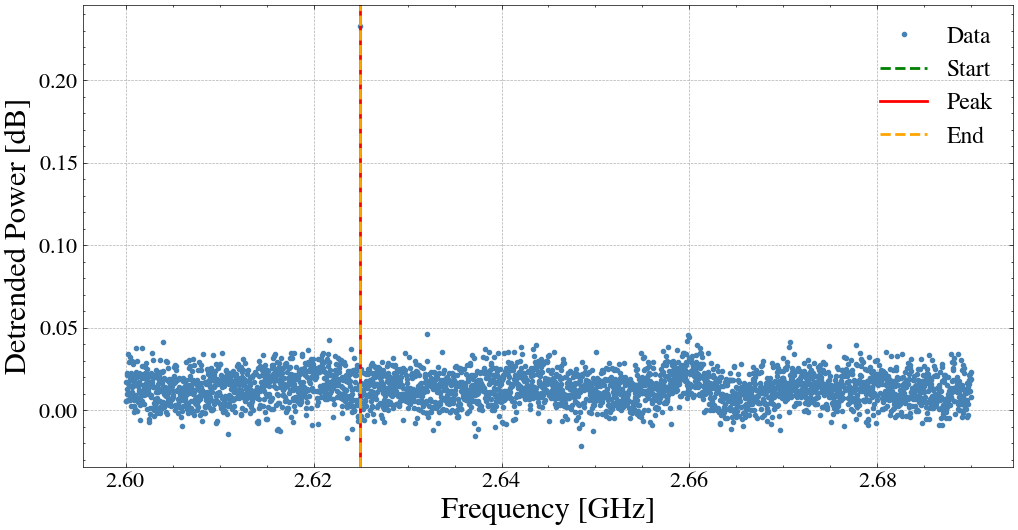

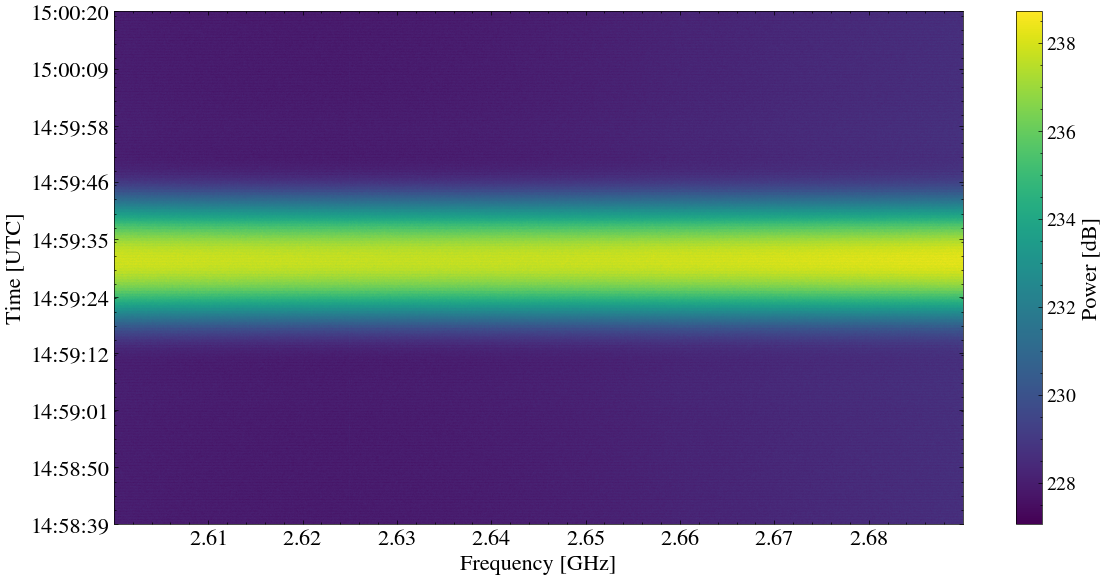

In [19]:
# The frequency 2.1703, 2.1703, 2.1723, 2.1841, are too close and are not very well defined

mask1 = (freq > 1.814) & (freq < 1.83) # IMT1800 BTX (Cellphone Downlink) GSM 1800
mask2 = (freq > 1.87) & (freq < 1.874) # IMT1800 BTX (Cellphone Downlink) GSM 1800
mask3 = (freq > 2.00) & (freq < 2.006) # Mobile Satellite Uplink (Earth to Space)
mask4 = (freq > 2.09) & (freq < 2.098) # Space Operations (Earth to Space and vice versa)
mask5 = (freq > 2.197) & (freq < 2.203) # Mobile Satellite Downlink (Space to Earth)
mask6 = (freq > 2.358) & (freq < 2.368) # Fixed Wireless Access Point to Point/Point to Multipoint #5G
mask7 = (freq > 2.491) & (freq < 2.493) # Mobile Satellite Services # ITU Resolution 249 (Rev.WRC‑23);
mask8 = (freq > 2.6) & (freq < 2.69) # ICASA (Independent Communications Authority of South Africa) Frequency Plan ???


fitted = quantify_RFI_width(freq[mask8], power_base_core[mask8])
waterfall = waterfall_timevsfreq1(time, freq, spectrum, mask8)


--- Analyzing Mask 1 ---
Start Frequency: 1.8164 GHz
End Frequency: 1.8271 GHz
Peak Frequency: 1.8196 GHz with Power: 7.3196 dB
Number off corrupted channels:  400.0


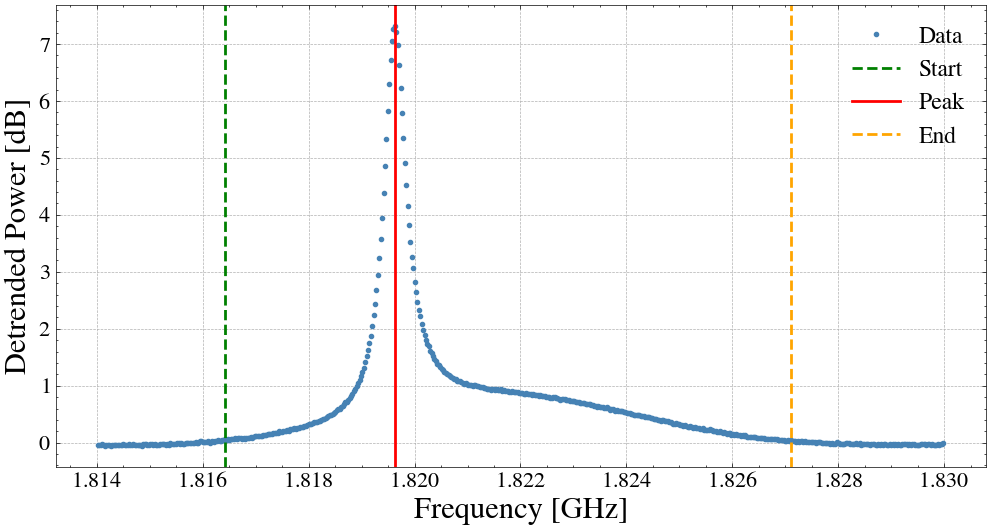

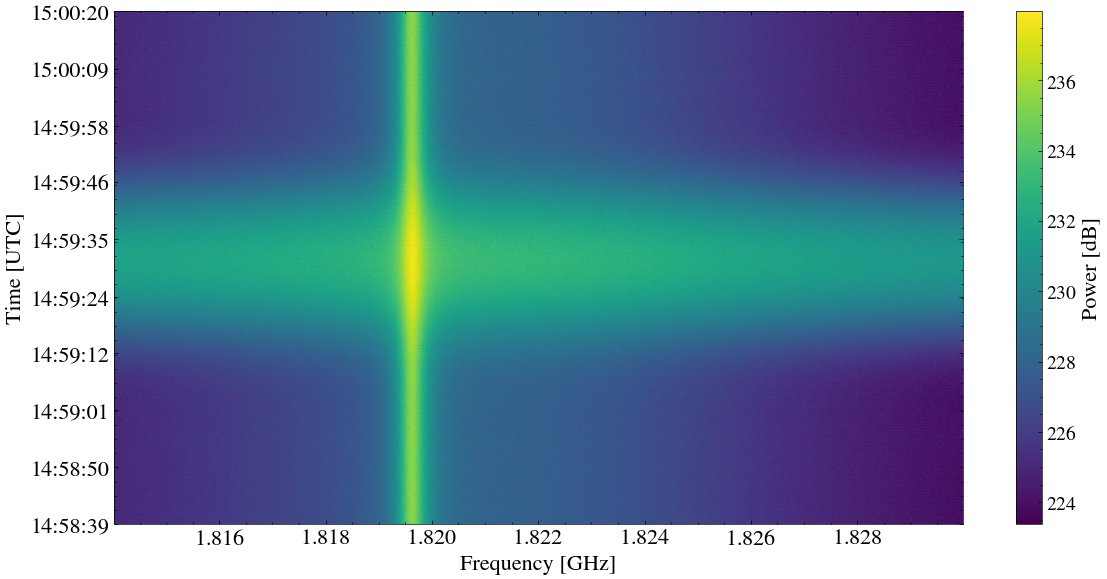


--- Analyzing Mask 2 ---
Start Frequency: 1.8735 GHz
End Frequency: 1.8737 GHz
Peak Frequency: 1.8735 GHz with Power: 0.1646 dB
Number off corrupted channels:  7.0


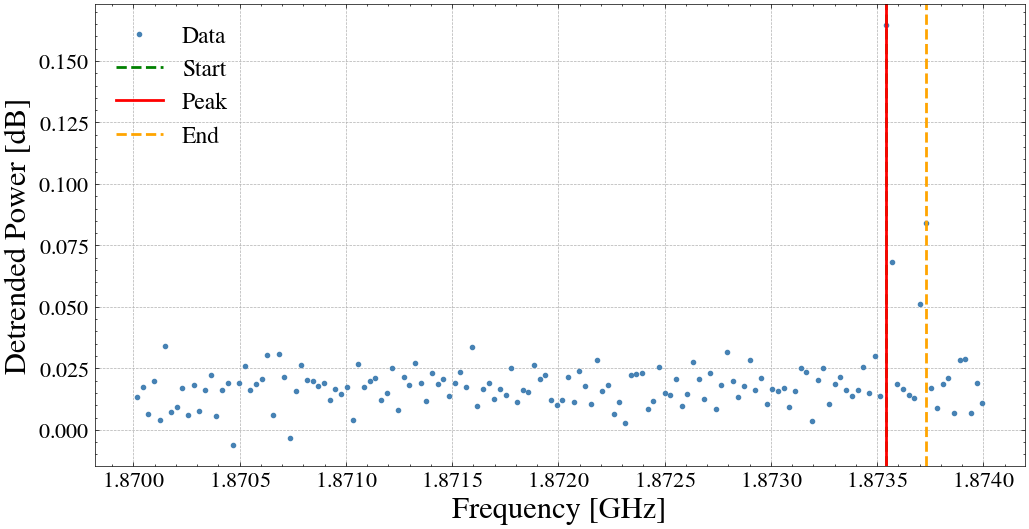

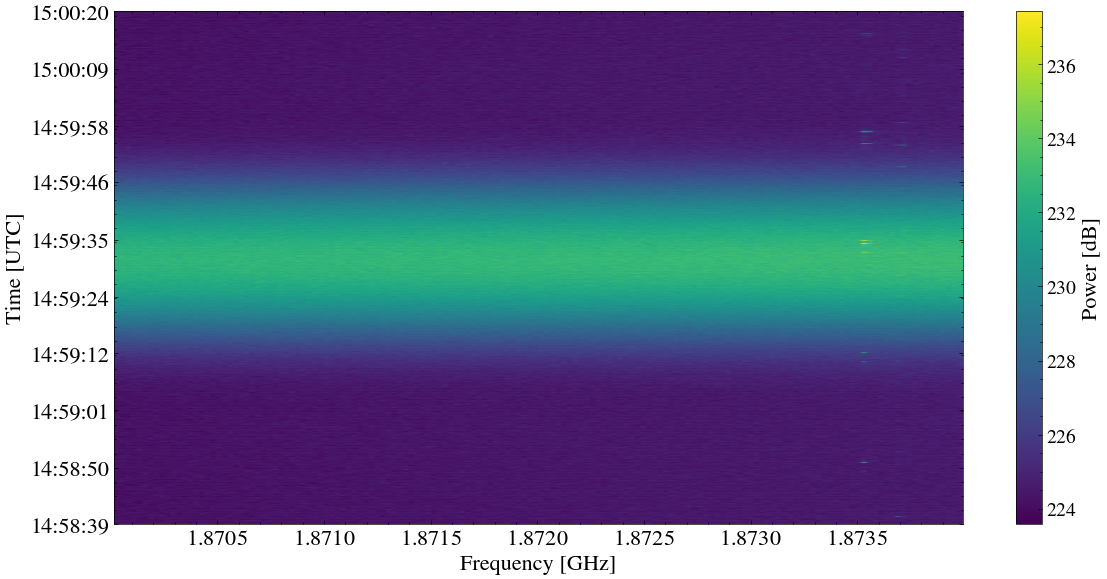


--- Analyzing Mask 3 ---
Start Frequency: 2.0003 GHz
End Frequency: 2.0048 GHz
Peak Frequency: 2.0028 GHz with Power: 10.2505 dB
Number off corrupted channels:  169.0


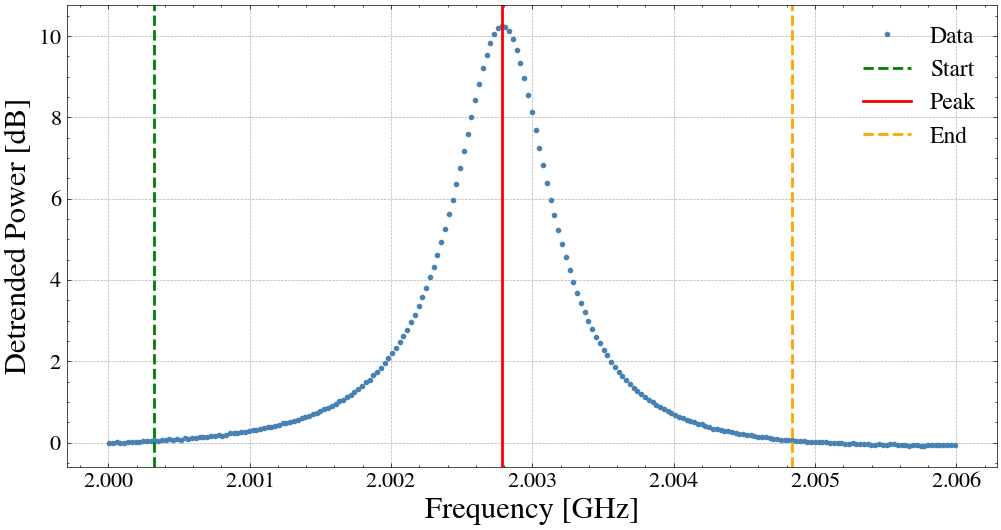

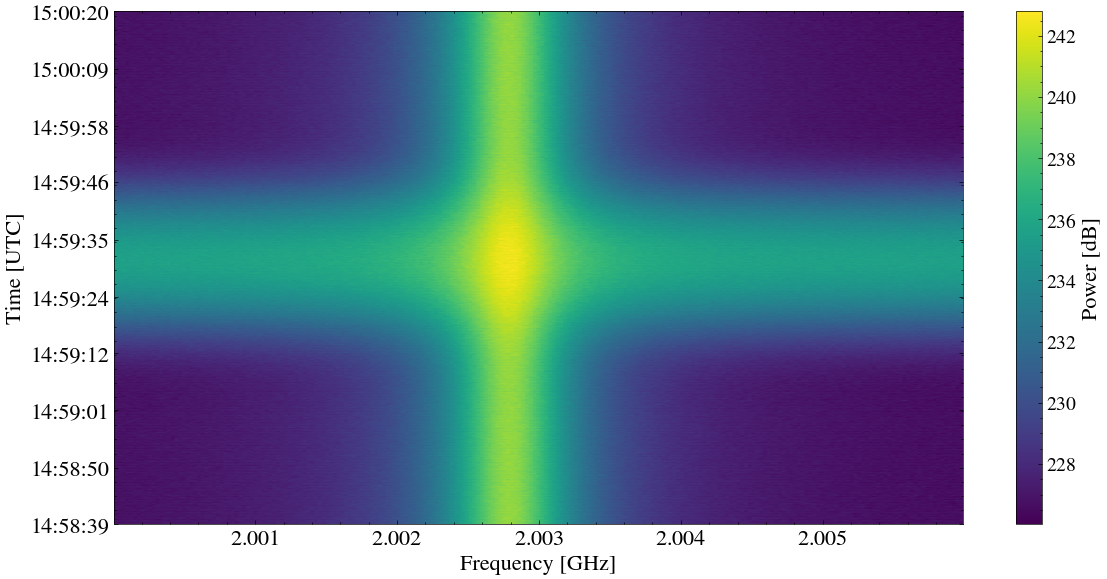


--- Analyzing Mask 4 ---
Start Frequency: 2.0935 GHz
End Frequency: 2.0956 GHz
Peak Frequency: 2.0935 GHz with Power: 0.0728 dB
Number off corrupted channels:  78.0


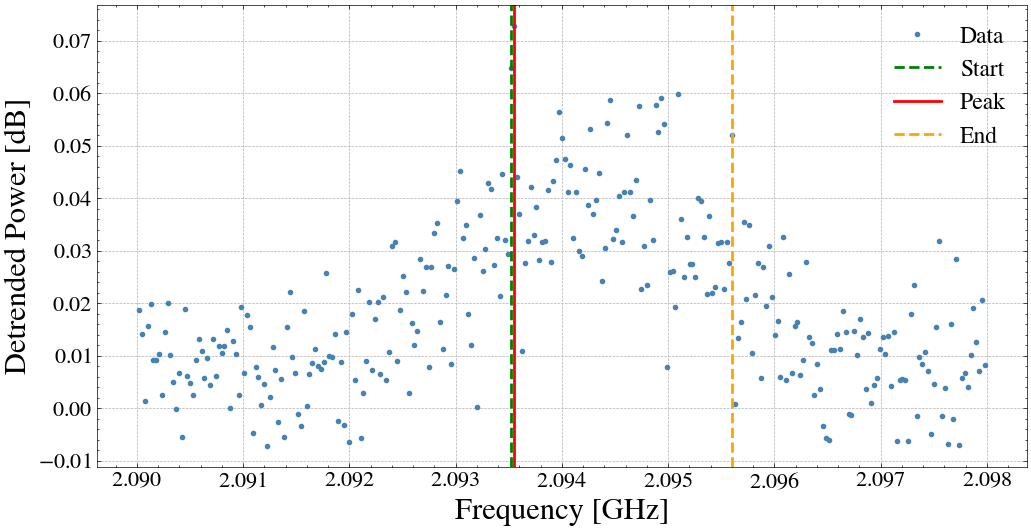

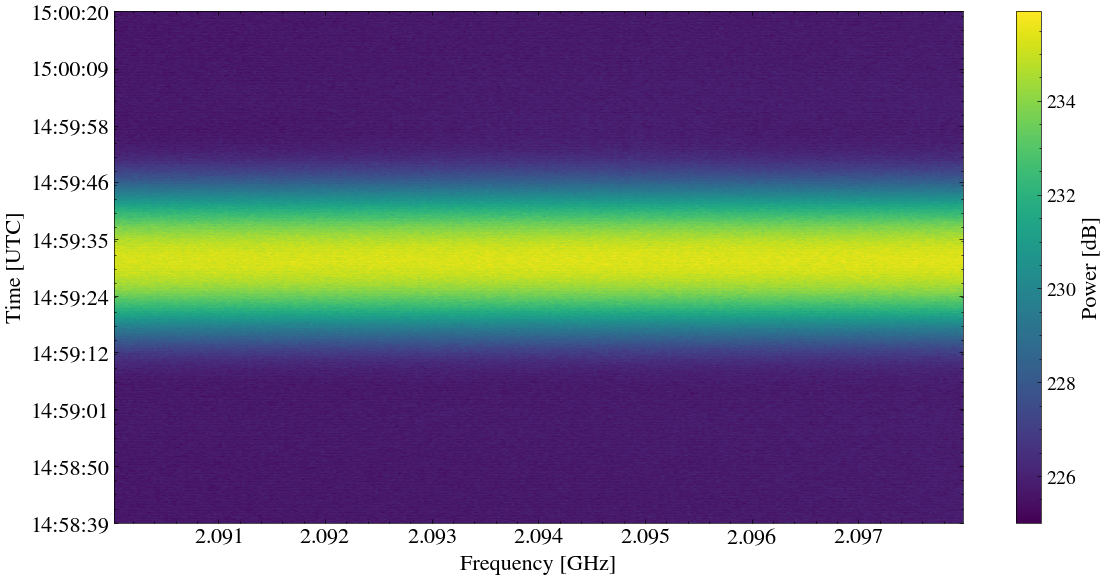


--- Analyzing Mask 5 ---
Start Frequency: 2.1975 GHz
End Frequency: 2.2020 GHz
Peak Frequency: 2.1999 GHz with Power: 8.3397 dB
Number off corrupted channels:  169.0


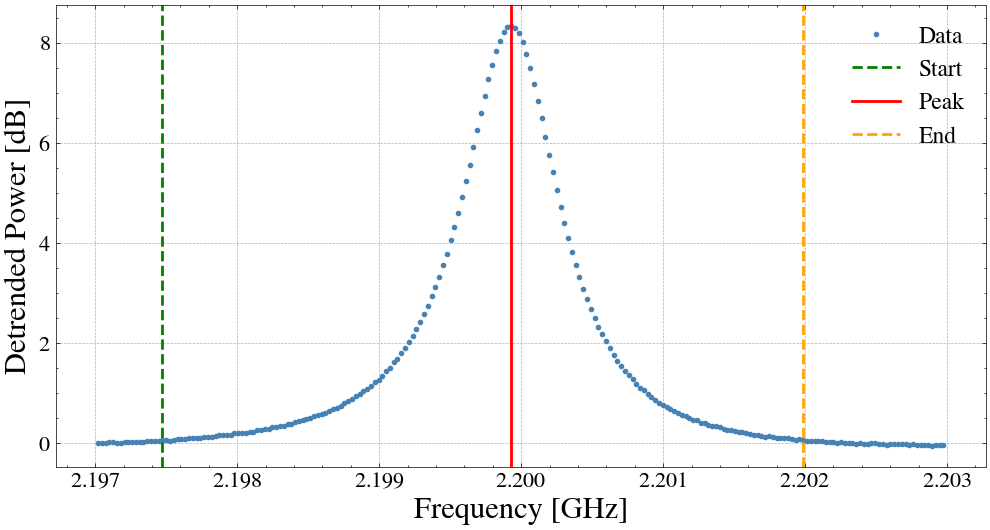

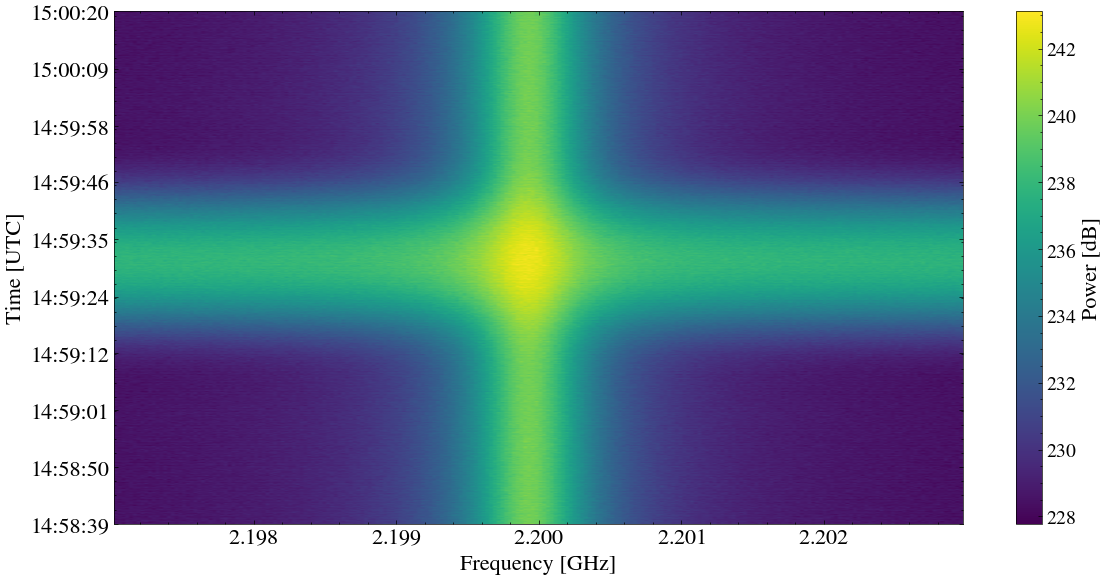


--- Analyzing Mask 6 ---
Start Frequency: 2.3606 GHz
End Frequency: 2.3655 GHz
Peak Frequency: 2.3627 GHz with Power: 0.6681 dB
Number off corrupted channels:  183.0


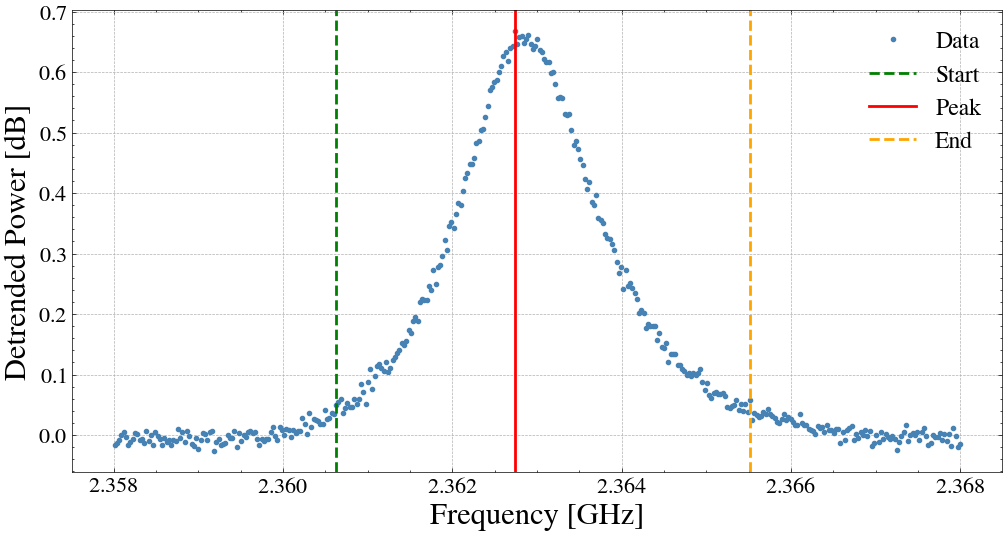

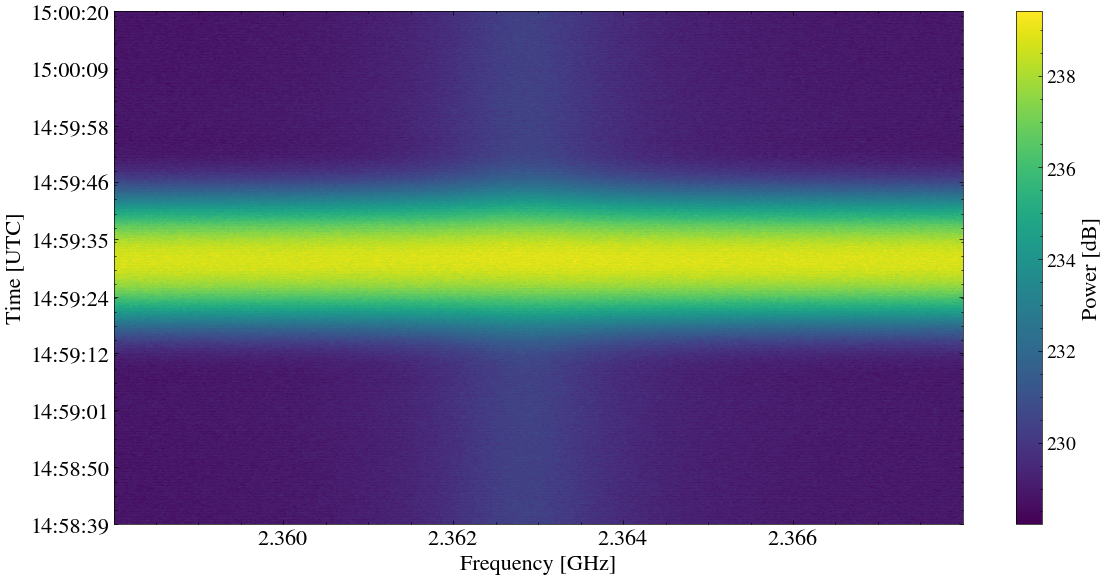


--- Analyzing Mask 7 ---
Start Frequency: 2.4914 GHz
End Frequency: 2.4926 GHz
Peak Frequency: 2.4920 GHz with Power: 3.3664 dB
Number off corrupted channels:  42.0


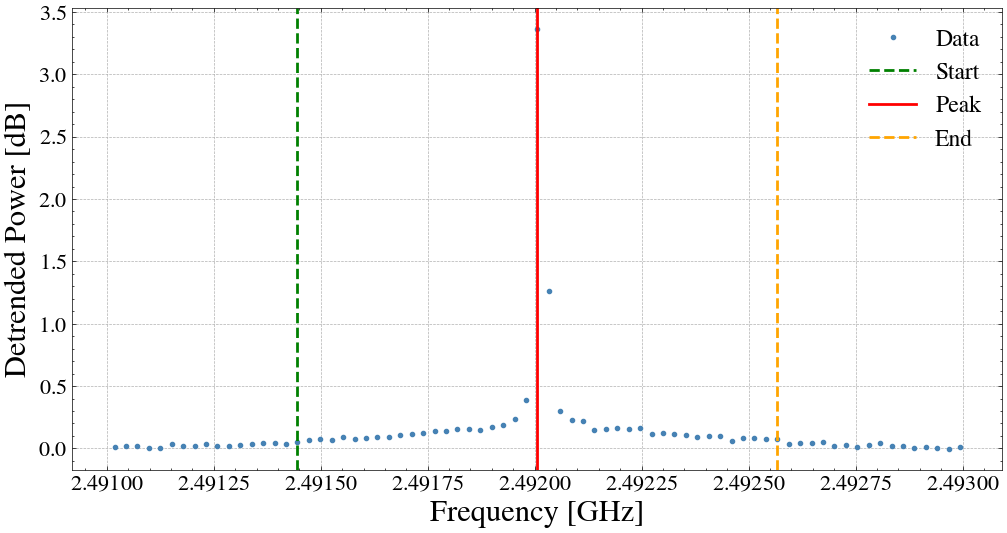

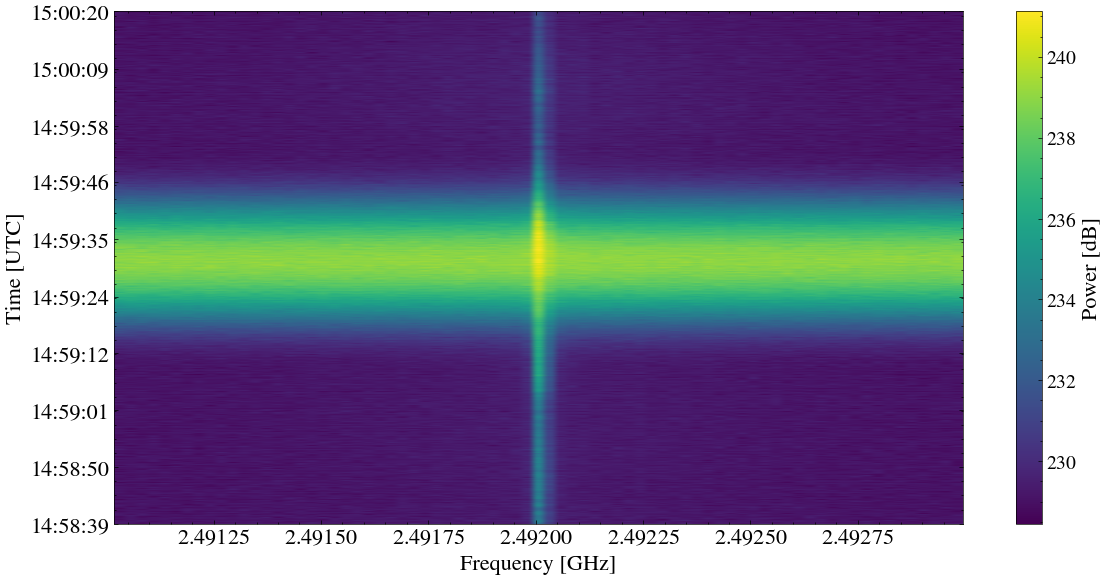


--- Analyzing Mask 8 ---
Start Frequency: 2.6250 GHz
End Frequency: 2.6250 GHz
Peak Frequency: 2.6250 GHz with Power: 0.2329 dB
Number off corrupted channels:  0.0


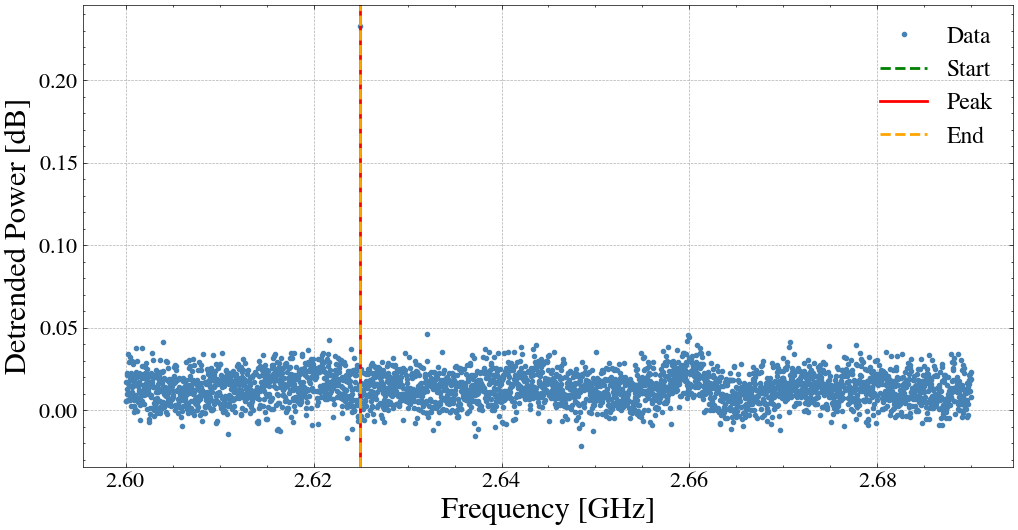

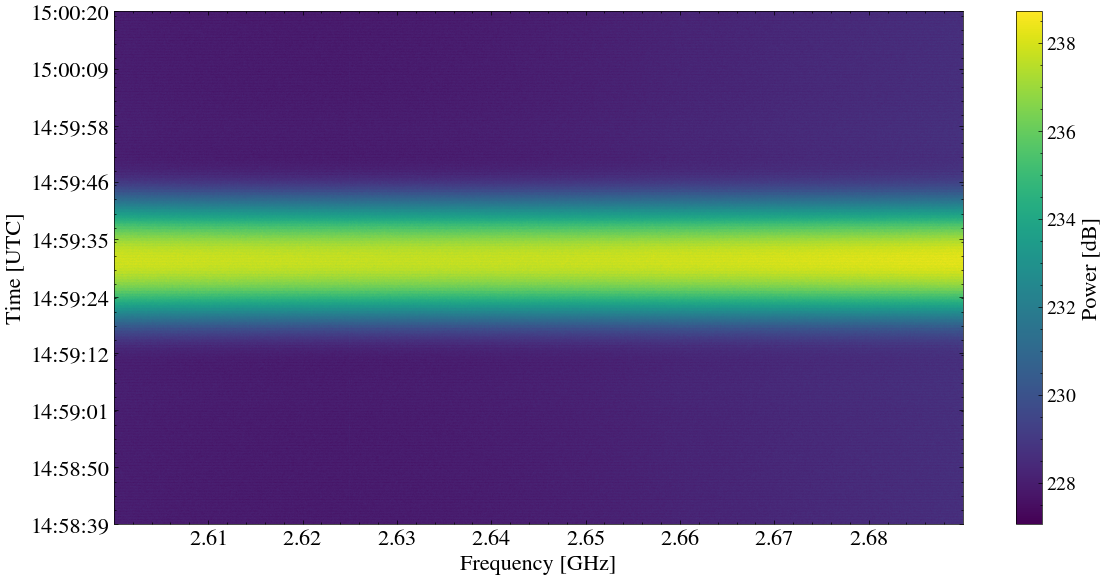

In [20]:
mask = [mask1, mask2, mask3, mask4, mask5, mask6, mask7, mask8]
mask_high = [mask1, mask3, mask5, mask6, mask7]
mask_low = [mask2, mask4, mask8]

for i, m in enumerate(mask):
    print(f"\n--- Analyzing Mask {i+1} ---")

    fitted = quantify_RFI_width(freq[m], power_base_core[m])
    # plt.savefig(f'/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/quatify_RFI_mask_{i+1}.png', dpi=300)
    # plt.savefig(f'/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/quatify_RFI_mask_{i+1}.pdf', dpi=300)
    plt.show()


    waterfall = waterfall_timevsfreq1(time, freq, spectrum, m)   
    # plt.savefig(f'/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/Waterfall_mask_{i+1}.png', dpi=300)
    # plt.savefig(f'/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/Waterfall_mask_{i+1}.pdf', dpi=300)
    plt.show()

    #break

# Investigate the 18:41 to 18:42

In [21]:
# find theindex of the time in utc format
time_utc = pd.to_datetime(time, unit="s", utc=True)
formatted_time = time_utc.strftime('%H:%M:%S')
formatted_time

Index(['14:58:39', '14:58:39', '14:58:39', '14:58:39', '14:58:39', '14:58:39',
       '14:58:40', '14:58:40', '14:58:40', '14:58:40',
       ...
       '15:00:19', '15:00:19', '15:00:19', '15:00:19', '15:00:20', '15:00:20',
       '15:00:20', '15:00:20', '15:00:20', '15:00:20'],
      dtype='str', length=664)

In [22]:
date = time_utc[0].date()
start = pd.Timestamp(f'{date} 18:41:49', tz='UTC')
end = pd.Timestamp(f'{date} 18:42:12', tz='UTC')
indices = np.where((time_utc >= start) & (time_utc <= end))[0]
indices

array([], dtype=int64)

In [23]:
# select the time window and frequency mask
time_window = (time_utc >= start) & (time_utc <= end)

In [24]:
time_mask1 = (formatted_time > '18:41:49') & (formatted_time < '18:42:12')
time_mask2 = (formatted_time > '18:41:49') & (formatted_time < '18:42:12')

/tmp/ipykernel_1144743/1441750579.py:4: RuntimeWarning: Mean of empty slice
  spectrum_window = spectrum_db[indices, :].mean(axis=0)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/numpy/_core/_methods.py:134: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


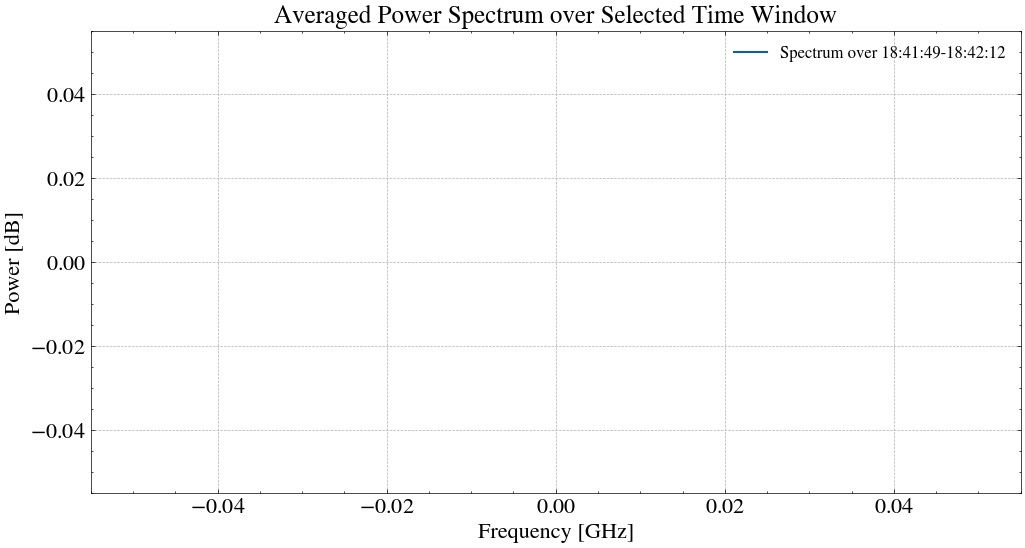

In [25]:
spectrum_db = 10 * np.log10(spectrum**2 + 1e-12)

# let's select a time window and average the spectrum over that window
spectrum_window = spectrum_db[indices, :].mean(axis=0)
time_window = time_utc[indices]


plt.figure(figsize=(12,6))
plt.plot(freq[mask6], spectrum_window[mask6], label='Spectrum over 18:41:49-18:42:12', lw=1.5)
plt.xlabel("Frequency [GHz]", fontsize=16)
plt.ylabel("Power [dB]", fontsize=16)
plt.title("Averaged Power Spectrum over Selected Time Window", fontsize=18)
plt.grid(linestyle='--')
plt.legend(fontsize=12)

In [26]:
freq[mask6].shape

(375,)

# Broad band RFI source around time domain


# MeerKat extension S band from SKAMPI_DATA.

# How to I identify astronomical and non-astronomical sources?


# I need to plot azimute and elevation ? -> Right ascention and declination
From the Ra and Dec find the source observed!


# How to apply the correlation to find if a certain RFI is appearing in all scans/antennas?


# The unknow RFI characterize them and calculat




# write a code which alows to zoom-in the plot to a certain window of frequency.

bokeh -  library for interactive visualizations

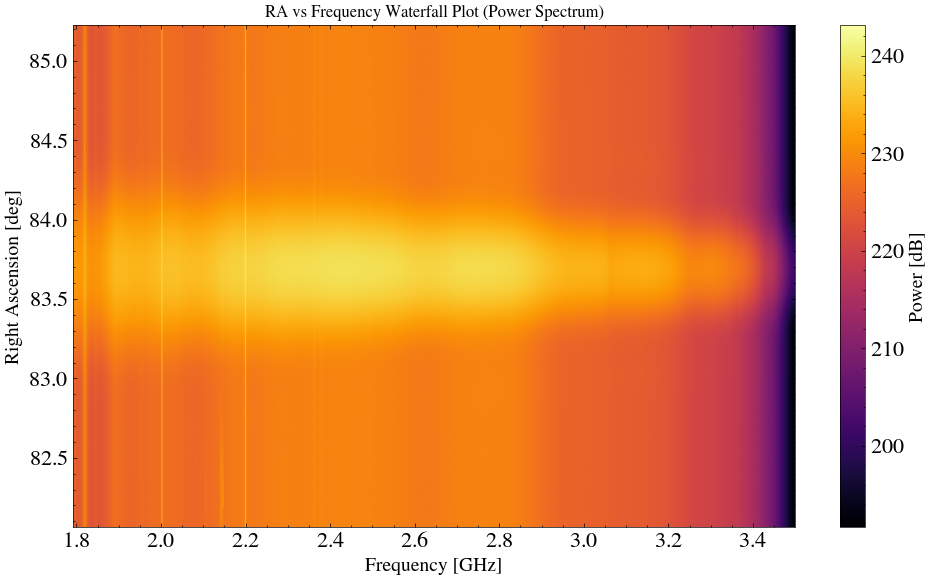

In [27]:


with h5py.File(filename, 'r') as f:
    for g in groups:
            
        spectrum = f[f"{g}/spectrum"][:, 1600:-60]   # (time x freq)
        freq = f[f"{g}/frequency"][1600:-60] / 1e9   # GHz
        ra = f[f"{g}/ra"][:]                        # deg

# --- Convert power to dB (optional, for visual clarity) ---
spectrum_db = 10 * np.log10(spectrum**2)

# --- Plot RA vs Frequency heatmap ---
plt.figure(figsize=(10, 6))
im = plt.imshow(
    spectrum_db,
    aspect='auto',           # preserve relative axes
    origin='lower',
    extent=[freq.min(), freq.max(), ra.min(), ra.max()],
    cmap='inferno'           # or 'viridis', 'plasma', etc.
)
plt.colorbar(im, label='Power [dB]')
plt.xlabel('Frequency [GHz]')
plt.ylabel('Right Ascension [deg]')
plt.title('RA vs Frequency Waterfall Plot (Power Spectrum)')
plt.tight_layout()
plt.show()


In [28]:
print(f'Ra shape {ra.shape}')
print(f'spectrum shape {spectrum.shape}')

Ra shape (664,)
spectrum shape (664, 63877)


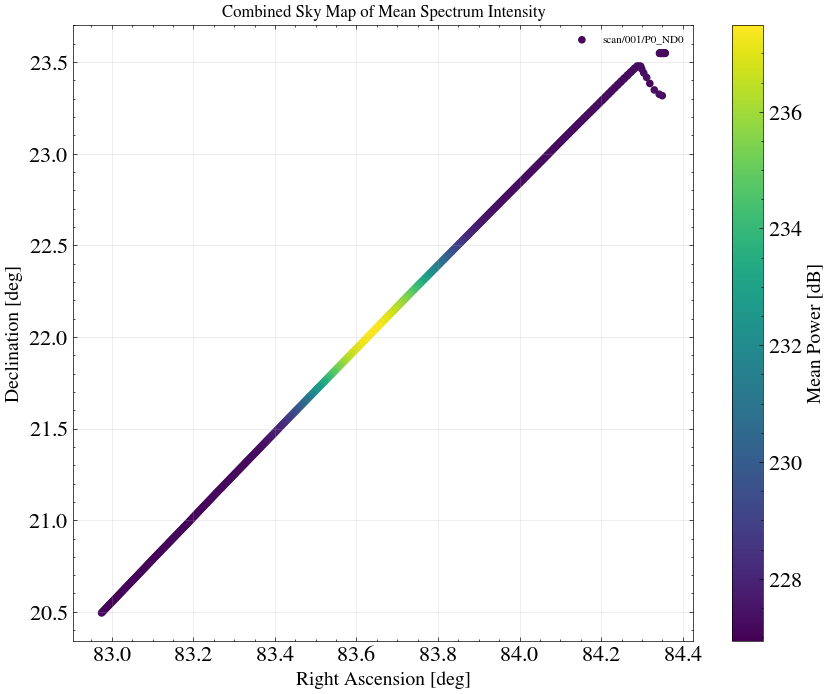

In [29]:
groups1 = [
    #"scan/000/P1_ND0",
     #"scan/000/P1_ND1",
    "scan/001/P0_ND0",
     #"scan/001/P0_ND1",
     #"scan/001/P1_ND0",
    # "scan/001/P1_ND1"
]

# Create one figure before the loop
plt.figure(figsize=(10, 8))

with h5py.File(filename, 'r') as f:
    for g in groups1:
        # --- Load data ---
        spectrum = f[f"{g}/spectrum"][:, 1600:-60]   # (time x freq)
        freq = f[f"{g}/frequency"][1600:-60] / 1e9   # GHz
        ra = f[f"{g}/ra"][:]                        # deg
        dec = f[f"{g}/dec"][:]                      # deg

        # --- Compute mean power per time sample ---
        mean_power = 10 * np.log10(np.mean(spectrum**2, axis=1))

        # --- Overlay scatter for this scan ---
        sc = plt.scatter(ra, dec, c=mean_power, cmap='viridis', s=20, label=g)

# --- After all scans are plotted ---
cbar = plt.colorbar(sc)
cbar.set_label("Mean Power [dB]")

plt.xlabel("Right Ascension [deg]")
plt.ylabel("Declination [deg]")
plt.title("Combined Sky Map of Mean Spectrum Intensity")
plt.grid(True, alpha=0.3)
plt.legend(loc='best', fontsize=8)
plt.show()


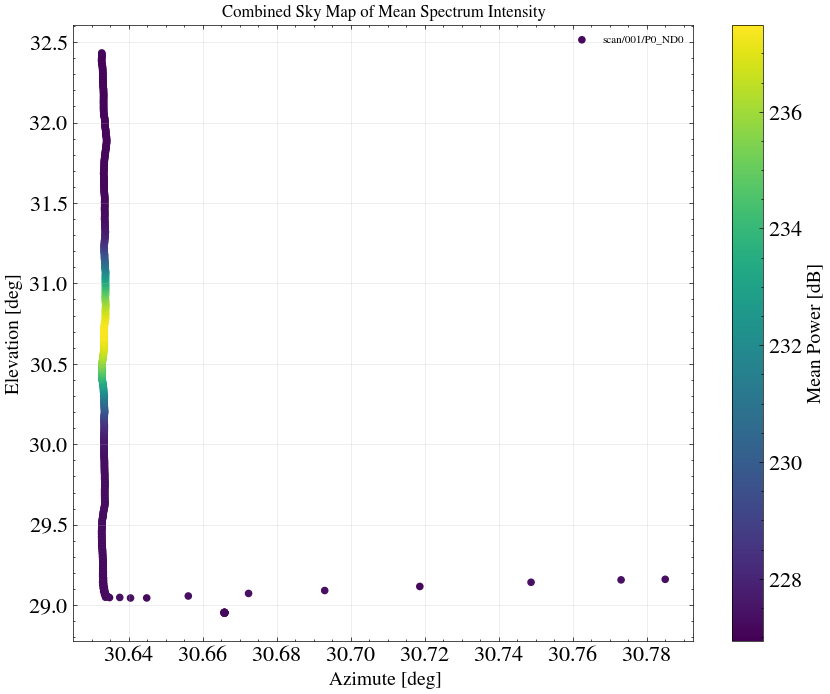

In [30]:

# Create one figure before the loop
plt.figure(figsize=(10, 8))

with h5py.File(filename, 'r') as f:
    for g in groups1:
        # --- Load data ---
        spectrum = f[f"{g}/spectrum"][:, 1600:-60]   # (time x freq)
        freq = f[f"{g}/frequency"][1600:-60] / 1e9   # GHz
        el = f[f"{g}/elevation"][:]                        # deg
        az = f[f"{g}/azimuth"][:]                      # deg

        # --- Compute mean power per time sample ---
        mean_power = 10 * np.log10(np.mean(spectrum**2, axis=1))

        # --- Overlay scatter for this scan ---
        sc = plt.scatter(az, el, c=mean_power, cmap='viridis', s=20, label=g)

# --- After all scans are plotted ---
cbar = plt.colorbar(sc)
cbar.set_label("Mean Power [dB]")

plt.xlabel(" Azimute [deg]")
plt.ylabel("Elevation [deg]")
plt.title("Combined Sky Map of Mean Spectrum Intensity")
plt.grid(True, alpha=0.3)
plt.legend(loc='best', fontsize=8)
plt.show()


Generating plot for: scan/000/P1_ND0


/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/numpy/_core/_methods.py:190: RuntimeWarning: overflow encountered in square
  x = um.square(x, out=x)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/numpy/_core/_methods.py:201: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(x, axis, dtype, out, keepdims=keepdims, where=where)


<module 'matplotlib.pyplot' from '/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/matplotlib/pyplot.py'>

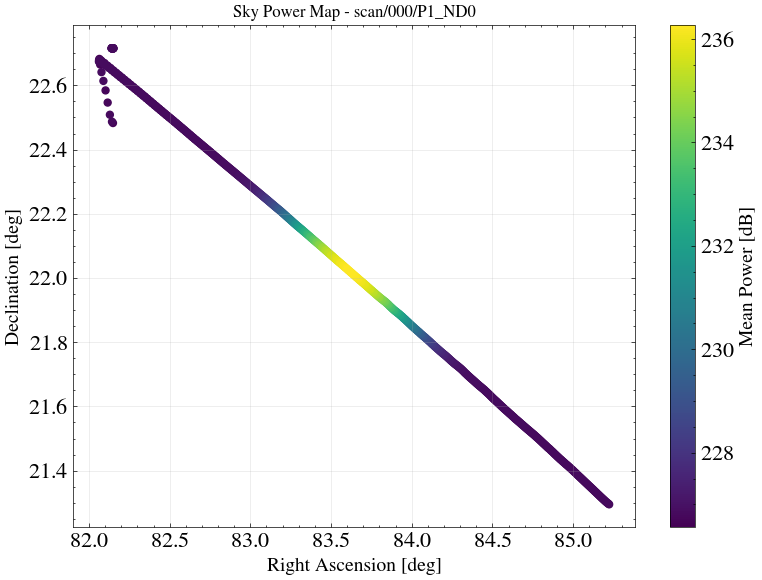

In [31]:

import numpy.ma as ma

with h5py.File(filename, 'r') as f:
        
    for g in groups:
        print(f"Generating plot for: {g}")

        # --- Load data from HDF5 file ---
        spectrum = f[f"{g}/spectrum"][:, 1600:-60]  # shape: (time, freq)
        freq = f[f"{g}/frequency"][1600:-60] / 1e9  # GHz
        ra = f[f"{g}/ra"][:]                       # degrees
        dec = f[f"{g}/dec"][:]                     # degrees

        # --- Compute statistics for coloring ---
        # Use mean power over frequency channels (can replace with np.median)
        mean_power = 10 * np.log10(np.mean(spectrum**2, axis=1))
        std_power  = 10 * np.log10(np.std(spectrum**2, axis=1))

        # --- Optional: mask out invalid or noisy data (if you have a mask) ---
        # Example dummy mask (can replace with your own final_mask logic)
        # merged_edge_mask_invert = np.invert(final_mask[g].astype(bool))
        # power_masked = ma.masked_array(mean_power, mask=merged_edge_mask_invert, fill_value=np.nan)

        # --- Sort data for cleaner plotting (optional) ---
        sort_idx = np.argsort(mean_power)
        ra_sort  = ra[sort_idx]
        dec_sort = dec[sort_idx]
        power    = mean_power[sort_idx]

        # --- Plot RA vs Dec scatter colored by power ---
        plt.figure(figsize=(8, 6))
        sc = plt.scatter(ra_sort, dec_sort, c=power, cmap='viridis', s=25)
        plt.colorbar(sc, label="Mean Power [dB]")
        plt.xlabel("Right Ascension [deg]")
        plt.ylabel("Declination [deg]")
        plt.title(f"Sky Power Map - {g}")
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
plt

# I need to plot azimute and elevation ? -> Right ascention and declination


For each for observing dates are the RFI in both polarization same or diferente?

Po - on the right and P1 - left 


